# Bài 06 - Phần 2: Phân tích hai bộ dữ liệu

Notebook này xem xét hai bộ dữ liệu trước khi đưa vào mạng hồi quy:

1. **Churn Modelling**: 10.000 khách hàng của một ngân hàng, mỗi người một dòng, cột
   `Exited` cho biết khách đã rời ngân hàng hay chưa. Lấy từ repo
   <https://github.com/HarshitWaldia/Churn_Modelling>.
2. **Amazon (AMZN)**: giá cổ phiếu theo ngày từ 15/05/1997 đến 05/12/2023, lấy từ
   Kaggle `henryshan/amazon-com-inc-amzn`.

Mục tiêu không chỉ là mô tả dữ liệu mà còn là trả lời hai câu hỏi quyết định cách dùng
RNN ở notebook 03 và 04: dữ liệu có trục thời gian thật hay không, và trong chuỗi giá
thì phần nào dự báo được, phần nào không.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import lab06_data as D

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)


def save(fig, name):
    fig.savefig(D.RESULTS / name, bbox_inches="tight")

## 1. Churn Modelling: hành vi rời bỏ của khách hàng ngân hàng

### 1.1. Cấu trúc bảng

In [2]:
df = D.load_churn()
print("kich thuoc:", df.shape)
df.head()

kich thuoc: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
info = pd.DataFrame({"kieu": df.dtypes.astype(str),
                     "so_gia_tri_khac_nhau": df.nunique(),
                     "so_o_trong": df.isna().sum()})
print(info)
print("\ndong trung lap:", df.duplicated().sum(),
      "| CustomerId trung:", df["CustomerId"].duplicated().sum())

                    kieu  so_gia_tri_khac_nhau  so_o_trong
RowNumber          int64                 10000           0
CustomerId         int64                 10000           0
Surname              str                  2932           0
CreditScore        int64                   460           0
Geography            str                     3           0
Gender               str                     2           0
Age                int64                    70           0
Tenure             int64                    11           0
Balance          float64                  6382           0
NumOfProducts      int64                     4           0
HasCrCard          int64                     2           0
IsActiveMember     int64                     2           0
EstimatedSalary  float64                  9999           0
Exited             int64                     2           0

dong trung lap: 0 | CustomerId trung: 0


Không có ô trống, không có dòng trùng, mỗi `CustomerId` xuất hiện đúng một lần. Ba
cột `RowNumber`, `CustomerId`, `Surname` chỉ là định danh: giữ lại thì mô hình có thể
học thuộc lòng từng người thay vì học quy luật, nên bị bỏ đi. Còn lại 10 đặc trưng
đầu vào và một nhãn.

Điều quan trọng nhất cần thấy ngay từ bảng này: **mỗi khách hàng chỉ có một dòng**.
Đây là ảnh chụp tại một thời điểm, không phải lịch sử giao dịch theo tháng. Yếu tố
thời gian duy nhất là `Tenure` (số năm đã gắn bó với ngân hàng) và `Age`. Mục 1.6 đo
xem `Tenure` có liên quan tới việc rời bỏ hay không.

In [4]:
print(df.describe().T.round(2))

                   count         mean       std          min          25%          50%          75%          max
RowNumber        10000.0      5000.50   2886.90         1.00      2500.75      5000.50      7500.25     10000.00
CustomerId       10000.0  15690940.57  71936.19  15565701.00  15628528.25  15690738.00  15753233.75  15815690.00
CreditScore      10000.0       650.53     96.65       350.00       584.00       652.00       718.00       850.00
Age              10000.0        38.92     10.49        18.00        32.00        37.00        44.00        92.00
Tenure           10000.0         5.01      2.89         0.00         3.00         5.00         7.00        10.00
Balance          10000.0     76485.89  62397.41         0.00         0.00     97198.54    127644.24    250898.09
NumOfProducts    10000.0         1.53      0.58         1.00         1.00         1.00         2.00         4.00
HasCrCard        10000.0         0.71      0.46         0.00         0.00         1.00         1

### 1.2. Nhãn mất cân bằng

In [5]:
counts = df["Exited"].value_counts().sort_index()
rate = df["Exited"].mean()
print(counts.to_string())
print("ty le roi bo: %.2f%%" % (100 * rate))

Exited
0    7963
1    2037
ty le roi bo: 20.37%


Chỉ 20,37% khách rời bỏ. Một mô hình luôn đoán "ở lại" đã đạt độ chính xác 79,63%,
nên độ chính xác không phải thước đo phù hợp. Notebook 03 và 04 dùng ROC-AUC, PR-AUC
và F1 của lớp rời bỏ, với ngưỡng quyết định chọn trên tập validation.

### 1.3. Tỷ lệ rời bỏ theo từng đặc trưng rời rạc

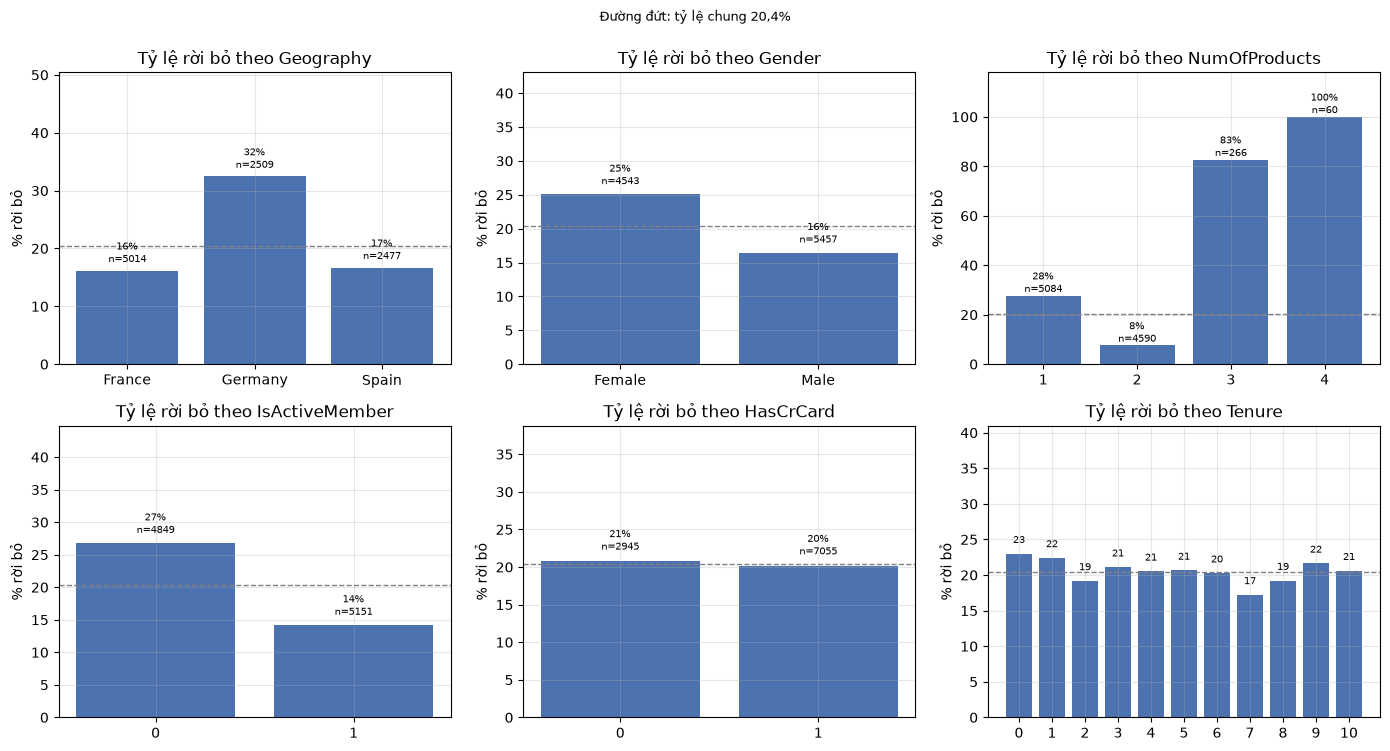

In [6]:
cats = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard", "Tenure"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, c in zip(axes.ravel(), cats):
    g = df.groupby(c)["Exited"].agg(["mean", "size"])
    xs = np.arange(len(g))
    ax.bar(xs, g["mean"] * 100, color="#4C72B0")
    ax.axhline(rate * 100, ls="--", c="gray", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        label = "%.0f%%\nn=%d" % (m * 100, n) if len(g) <= 4 else "%.0f" % (m * 100)
        ax.text(i, m * 100 + 1.5, label, ha="center", fontsize=7.5)
    ax.set_xticks(xs, g.index.astype(str))
    ax.set_ylim(0, max(g["mean"] * 100) + 18)
    ax.set_title("Tỷ lệ rời bỏ theo " + c)
    ax.set_ylabel("% rời bỏ")
fig.suptitle("Đường đứt: tỷ lệ chung 20,4%", fontsize=9, y=0.995)
fig.tight_layout()
save(fig, "fig_churn_categorical.png")
plt.show()

In [7]:
for c in cats:
    g = df.groupby(c)["Exited"].agg(["mean", "size"])
    print(c, "->", ", ".join("%s: %.1f%% (n=%d)" % (k, 100 * m, n)
                             for k, (m, n) in g.iterrows()))

Geography -> France: 16.2% (n=5014), Germany: 32.4% (n=2509), Spain: 16.7% (n=2477)
Gender -> Female: 25.1% (n=4543), Male: 16.5% (n=5457)
NumOfProducts -> 1: 27.7% (n=5084), 2: 7.6% (n=4590), 3: 82.7% (n=266), 4: 100.0% (n=60)
IsActiveMember -> 0: 26.9% (n=4849), 1: 14.3% (n=5151)
HasCrCard -> 0: 20.8% (n=2945), 1: 20.2% (n=7055)
Tenure -> 0: 23.0% (n=413), 1: 22.4% (n=1035), 2: 19.2% (n=1048), 3: 21.1% (n=1009), 4: 20.5% (n=989), 5: 20.7% (n=1012), 6: 20.3% (n=967), 7: 17.2% (n=1028), 8: 19.2% (n=1025), 9: 21.6% (n=984), 10: 20.6% (n=490)


Bốn đặc trưng tách nhóm rất rõ:

- **Geography**: khách ở Đức rời bỏ 32,4%, gấp đôi Pháp (16,2%) và Tây Ban Nha (16,7%).
- **NumOfProducts**: đây là quan hệ không đơn điệu. Dùng 2 sản phẩm chỉ 7,6% rời bỏ,
  dùng 1 sản phẩm 27,7%, còn 3 sản phẩm là 82,7% và 4 sản phẩm là 100% (60 người).
  Một mô hình tuyến tính theo `NumOfProducts` không thể biểu diễn hình chữ U này.
- **IsActiveMember**: khách không hoạt động rời bỏ 26,9% so với 14,3%.
- **Gender**: nữ 25,1%, nam 16,5%.

Hai đặc trưng gần như không tách nhóm: `HasCrCard` (20,8% so với 20,2%) và `Tenure`
(từ 17,2% đến 23,0% mà không có xu hướng). Như vậy **thời gian gắn bó với ngân hàng
hầu như không nói gì về việc rời bỏ**, điều sẽ quay lại ở mục 1.6.

### 1.4. Đặc trưng liên tục theo hai nhóm

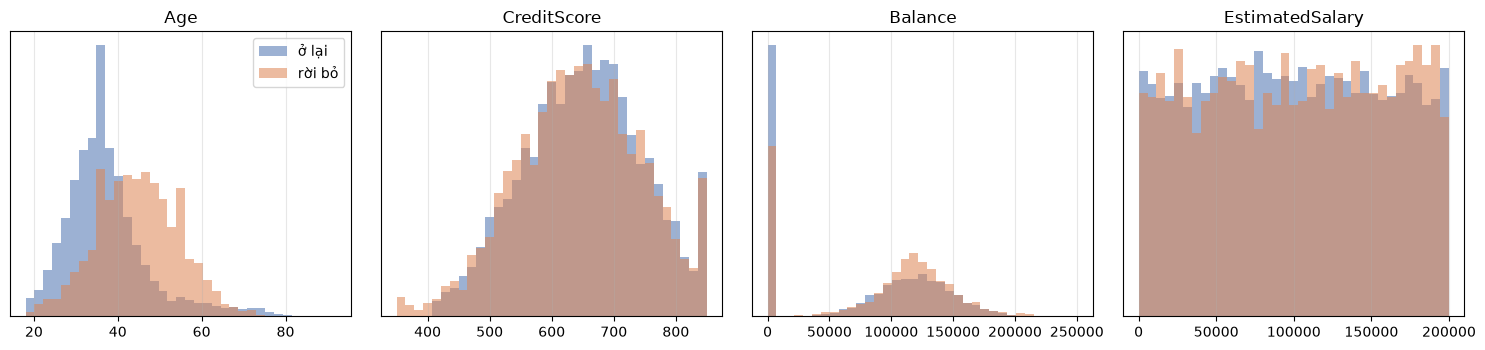

In [8]:
nums = ["Age", "CreditScore", "Balance", "EstimatedSalary"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, nums):
    bins = np.histogram_bin_edges(df[c], bins=35)
    for lab, col, name in [(0, "#4C72B0", "ở lại"), (1, "#DD8452", "rời bỏ")]:
        ax.hist(df.loc[df["Exited"] == lab, c], bins=bins, density=True, alpha=0.55,
                color=col, label=name)
    ax.set_title(c)
    ax.set_yticks([])
axes[0].legend()
fig.tight_layout()
save(fig, "fig_churn_numeric.png")
plt.show()

In [9]:
print(df.groupby("Exited")[nums].median().T.rename(columns={0: "o_lai", 1: "roi_bo"}))
print("\nKiem dinh Mann-Whitney (hai nhom co cung phan phoi khong):")
for c in nums:
    u = stats.mannwhitneyu(df.loc[df.Exited == 1, c], df.loc[df.Exited == 0, c])
    print("  %-16s p = %.2e" % (c, u.pvalue))

Exited              o_lai     roi_bo
Age                 36.00      45.00
CreditScore        653.00     646.00
Balance          92072.68  109349.29
EstimatedSalary  99645.04  102460.84

Kiem dinh Mann-Whitney (hai nhom co cung phan phoi khong):
  Age              p = 3.21e-230
  CreditScore      p = 1.99e-02
  Balance          p = 1.12e-28
  EstimatedSalary  p = 2.27e-01


`Age` là đặc trưng tách nhóm mạnh nhất: trung vị tuổi của nhóm rời bỏ là 45, nhóm ở
lại là 36. `Balance` có một đỉnh lớn ở 0 (36,2% khách có số dư bằng 0) và nhóm rời
bỏ có số dư trung vị cao hơn (109 nghìn so với 92 nghìn). `CreditScore` và `EstimatedSalary` gần như trùng nhau giữa hai
nhóm: kiểm định Mann-Whitney cho p = 0,02 với `CreditScore` (khác biệt có thật nhưng
rất nhỏ) và p = 0,23 với lương, tức không phân biệt được.

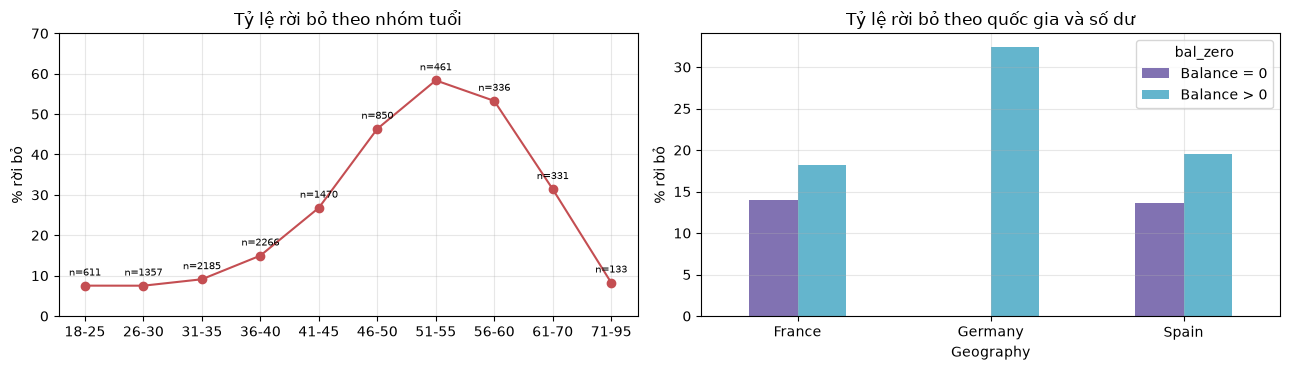

Age   (17, 25]  (25, 30]  (30, 35]  (35, 40]  (40, 45]  (45, 50]  (50, 55]  (55, 60]  (60, 70]  (70, 95]
pct        7.5       7.5       9.1      15.0      26.8      46.4      58.4      53.3      31.4       8.3
size     611.0    1357.0    2185.0    2266.0    1470.0     850.0     461.0     336.0     331.0     133.0
bal_zero   Balance = 0  Balance > 0
Geography                          
France            13.9         18.2
Germany            NaN         32.4
Spain             13.6         19.6

So khach Duc co Balance = 0: 0


In [10]:
age_bins = [17, 25, 30, 35, 40, 45, 50, 55, 60, 70, 95]
age_grp = pd.cut(df["Age"], age_bins)
by_age = df.groupby(age_grp, observed=True)["Exited"].agg(["mean", "size"])
bal0 = df.assign(bal_zero=np.where(df["Balance"] == 0, "Balance = 0", "Balance > 0"))
by_bal = bal0.groupby(["Geography", "bal_zero"])["Exited"].mean().unstack() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8))
labels = ["%d-%d" % (iv.left + 1, iv.right) for iv in by_age.index]
a1.plot(labels, by_age["mean"] * 100, "o-", c="#C44E52")
for i, (m, n) in enumerate(zip(by_age["mean"], by_age["size"])):
    a1.text(i, m * 100 + 2.5, "n=%d" % n, ha="center", fontsize=7.5)
a1.set_title("Tỷ lệ rời bỏ theo nhóm tuổi")
a1.set_ylabel("% rời bỏ")
a1.set_ylim(0, 70)
by_bal.plot.bar(ax=a2, rot=0, color=["#8172B2", "#64B5CD"])
a2.set_title("Tỷ lệ rời bỏ theo quốc gia và số dư")
a2.set_ylabel("% rời bỏ")
fig.tight_layout()
save(fig, "fig_churn_age_balance.png")
plt.show()
print(by_age.assign(pct=lambda t: (100 * t["mean"]).round(1))[["pct", "size"]].T)
print(by_bal.round(1))
print("\nSo khach Duc co Balance = 0:", int(((df.Geography == "Germany") & (df.Balance == 0)).sum()))

Tỷ lệ rời bỏ theo tuổi tăng từ khoảng 8% ở nhóm dưới 35 lên đỉnh 58,4% ở nhóm 51-55,
rồi giảm lại còn 31,4% ở nhóm 61-70 và 8,3% ở nhóm trên 70. Lại một quan hệ không đơn điệu. Ở biểu đồ bên phải,
không có khách Đức nào có số dư bằng 0, trong khi ở Pháp và Tây Ban Nha khách có số
dư bằng 0 rời bỏ ít hơn khách có số dư. Hai đặc trưng `Geography` và `Balance` vì
thế tương tác với nhau, không cộng dồn đơn giản.

### 1.5. Tương quan giữa các đặc trưng

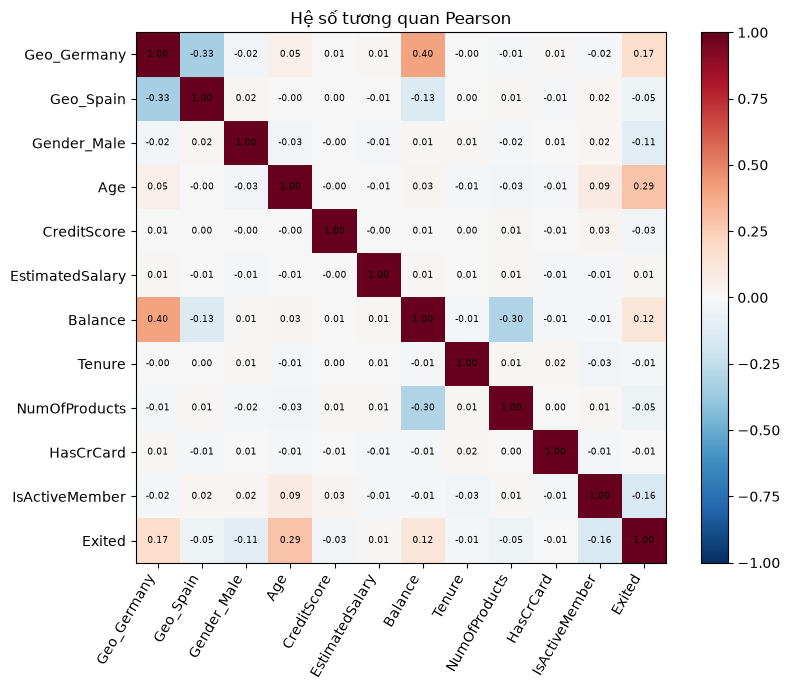

Age                0.285
Geo_Germany        0.173
IsActiveMember    -0.156
Balance            0.119
Gender_Male       -0.107
Geo_Spain         -0.053
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
EstimatedSalary    0.012
HasCrCard         -0.007
Name: Exited, dtype: float64


In [11]:
X_enc, y_all = D.churn_features(df)
corr_df = X_enc.assign(Exited=y_all).corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr_df, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_df)), corr_df.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr_df)), corr_df.columns)
for i in range(len(corr_df)):
    for j in range(len(corr_df)):
        ax.text(j, i, "%.2f" % corr_df.iloc[i, j], ha="center", va="center", fontsize=6.5)
ax.grid(False)
fig.colorbar(im, fraction=0.04)
ax.set_title("Hệ số tương quan Pearson")
fig.tight_layout()
save(fig, "fig_churn_corr.png")
plt.show()
print(corr_df["Exited"].drop("Exited").sort_values(key=np.abs, ascending=False).round(3))

Tương quan tuyến tính với nhãn cao nhất là `Age` (0,29), sau đó `Geo_Germany`
(0,17), `IsActiveMember` (-0,16), `Balance` (0,12). `NumOfProducts` chỉ có -0,05 dù ở
mục 1.3 nó là đặc trưng tách nhóm mạnh bậc nhất: hệ số Pearson chỉ đo quan hệ tuyến
tính nên bỏ sót hoàn toàn hình chữ U. Giữa các đặc trưng với nhau thì tương quan lớn
nhất là `Balance` với `Geo_Germany` (0,40) và `Balance` với `NumOfProducts` (-0,30),
không kể cặp `Geo_Germany` với `Geo_Spain` (-0,33) vốn do cách mã hóa one-hot. Không
có cặp nào gần như trùng lặp nên không cần bỏ bớt đặc trưng.

Kết luận thực tế: baseline hồi quy logistic sẽ bị giới hạn bởi hai quan hệ phi tuyến
(tuổi, số sản phẩm). Mạng nơ-ron, dù là MLP hay RNN, có lợi thế ở đây.

### 1.6. Yếu tố thời gian và cách đưa dữ liệu này vào RNN

In [12]:
ten = df.groupby("Tenure")["Exited"].mean() * 100
print("ty le roi bo theo Tenure: min %.1f%%, max %.1f%%, do lech chuan %.1f diem %%"
      % (ten.min(), ten.max(), ten.std()))
print("tuong quan Spearman(Tenure, Exited) = %.3f"
      % stats.spearmanr(df["Tenure"], df["Exited"]).statistic)

ty le roi bo theo Tenure: min 17.2%, max 23.0%, do lech chuan 1.6 diem %
tuong quan Spearman(Tenure, Exited) = -0.014


Đề bài gọi đây là dữ liệu "hành vi khách hàng theo thời gian", nhưng số liệu trên
cho thấy thời gian gắn bó không liên quan tới rời bỏ (tương quan Spearman xấp xỉ
0), và bộ dữ liệu không có chuỗi quan sát nào của cùng một khách hàng. Vì vậy bài
này không giả vờ rằng có chuỗi thời gian. Thay vào đó, mỗi khách hàng được biểu diễn
như **một chuỗi 11 bước, mỗi bước là một đặc trưng**, đọc theo thứ tự cố định: nhân
khẩu học (quốc gia, giới tính, tuổi), tài chính (điểm tín dụng, lương, số dư), rồi
quan hệ với ngân hàng (thâm niên, số sản phẩm, thẻ tín dụng, mức hoạt động). RNN đọc
từng bước và cập nhật trạng thái ẩn giống như một nhân viên đọc lần lượt từng dòng
của hồ sơ.

Cách làm này có một hệ quả cần kiểm tra chứ không được mặc nhiên: thứ tự của các
bước là do người làm chọn, không phải do dữ liệu quy định. Notebook 03 đo lại khi
đảo ngược và xáo trộn thứ tự, đồng thời so RNN với một MLP nhận cả 11 đặc trưng cùng
lúc để biết cấu trúc hồi quy có giúp gì không.

In [13]:
S = D.churn_splits()
for s in ("train", "val", "test"):
    print("%-5s X %s  ty le roi bo %.4f" % (s, S["X_" + s].shape, S["y_" + s].mean()))
print("thu tu RNN doc:", S["features"])
print("dang dua vao RNN:", S["X_train"][:, :, None].shape, "= (so khach, 11 buoc, 1 gia tri)")

train X (6400, 11)  ty le roi bo 0.2037
val   X (1600, 11)  ty le roi bo 0.2037
test  X (2000, 11)  ty le roi bo 0.2035
thu tu RNN doc: ['Geo_Germany', 'Geo_Spain', 'Gender_Male', 'Age', 'CreditScore', 'EstimatedSalary', 'Balance', 'Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']
dang dua vao RNN: (6400, 11, 1) = (so khach, 11 buoc, 1 gia tri)


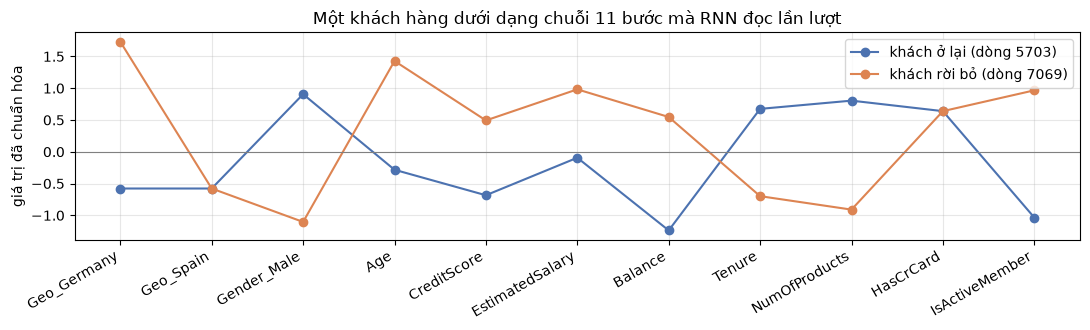

In [14]:
te = S["idx_test"]
i_stay = te[np.where(S["y_test"] == 0)[0][0]]
i_left = te[np.where(S["y_test"] == 1)[0][0]]
fig, ax = plt.subplots(figsize=(11, 3.4))
for k, (idx, name, col) in enumerate([(i_stay, "khách ở lại", "#4C72B0"),
                                      (i_left, "khách rời bỏ", "#DD8452")]):
    row = S["X_test"][list(te).index(idx)]
    ax.plot(range(11), row, "o-", c=col, label="%s (dòng %d)" % (name, idx + 1))
ax.axhline(0, c="gray", lw=0.8)
ax.set_xticks(range(11), S["features"], rotation=30, ha="right")
ax.set_ylabel("giá trị đã chuẩn hóa")
ax.set_title("Một khách hàng dưới dạng chuỗi 11 bước mà RNN đọc lần lượt")
ax.legend()
fig.tight_layout()
save(fig, "fig_churn_sequence_example.png")
plt.show()

Mỗi đặc trưng được chuẩn hóa về trung bình 0, độ lệch chuẩn 1 bằng thống kê của tập
train. Tập validation và test không được dùng để tính trung bình hay độ lệch, nên
không có thông tin nào của chúng lọt vào lúc huấn luyện.

## 2. Giá cổ phiếu Amazon (AMZN)

### 2.1. Cấu trúc và chất lượng dữ liệu

In [15]:
a = D.load_amzn()
print("kich thuoc:", a.shape, "| tu", a.index.min().date(), "den", a.index.max().date())
print(a.head(3))
print("o trong:", int(a.isna().sum().sum()))
print("Close trung Adj Close:", bool(np.allclose(a["Close"], a["Adj Close"])))
gaps = a.index.to_series().diff().dt.days
print("khoang cach giua hai phien (ngay lich):", gaps.value_counts().sort_index().head(6).to_dict())
print("khoang trong dai nhat: %d ngay, ket thuc %s" % (gaps.max(), gaps.idxmax().date()))
print("gia tri khong hop le: High < Low:", int((a.High < a.Low).sum()),
      "| Close ngoai [Low, High]:", int(((a.Close < a.Low - 1e-9) | (a.Close > a.High + 1e-9)).sum()))

kich thuoc: (6684, 6) | tu 1997-05-15 den 2023-12-05
                Open      High       Low     Close  Adj Close      Volume
Date                                                                     
1997-05-15  0.121875  0.125000  0.096354  0.097917   0.097917  1443120000
1997-05-16  0.098438  0.098958  0.085417  0.086458   0.086458   294000000
1997-05-19  0.088021  0.088542  0.081250  0.085417   0.085417   122136000
o trong: 0
Close trung Adj Close: True
khoang cach giua hai phien (ngay lich): {1.0: 5236, 2.0: 61, 3.0: 1207, 4.0: 176, 5.0: 2, 7.0: 1}
khoang trong dai nhat: 7 ngay, ket thuc 2001-09-17
gia tri khong hop le: High < Low: 0 | Close ngoai [Low, High]: 0


6.684 phiên giao dịch trong 26,5 năm, không có ô trống, không có dòng lỗi. `Close`
trùng hoàn toàn `Adj Close`: giá trong bộ dữ liệu đã được điều chỉnh theo các lần
chia tách cổ phiếu (gần nhất là 20 đổi 1 năm 2022), và Amazon không trả cổ tức nên
không có điều chỉnh nào khác. Khoảng trống dài nhất là tuần sau sự kiện
11/9/2001 khi sàn New York đóng cửa (phiên 10/9 rồi đến phiên 17/9), dài 7 ngày lịch.
Các khoảng 2-5 ngày còn lại là cuối tuần và ngày lễ.

Dữ liệu chia theo thời gian, **không xáo trộn**: train 1997-2018, validation
2019-2020, test 2021-2023. Nếu xáo trộn thì mô hình sẽ được học trên những ngày nằm
sau ngày nó phải dự báo, tức là nhìn thấy tương lai.

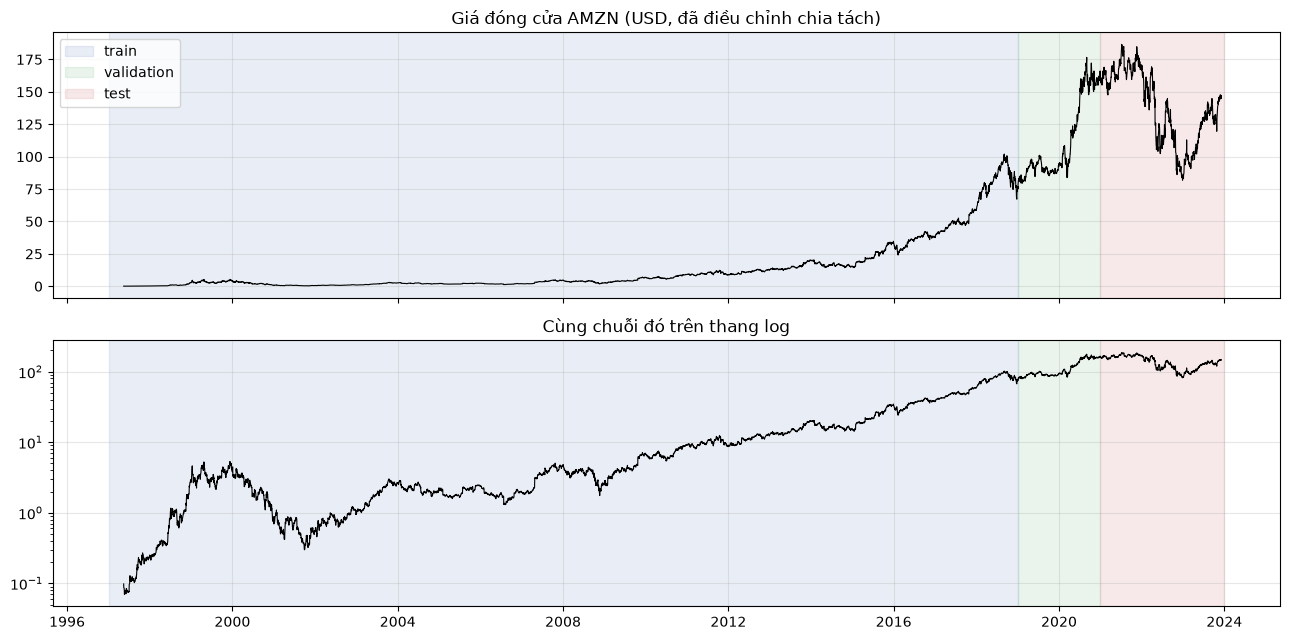

train       5443 phien, gia     0.10 ->    75.10 (min 0.07, max 101.98)
validation   505 phien, gia    76.96 ->   162.85 (min 75.01, max 176.57)
test         736 phien, gia   159.33 ->   146.88 (min 81.82, max 186.57)


In [16]:
f = D.stock_frame(a)
periods = [("1997", D.TRAIN_END, "train", "#4C72B0"),
           (D.TRAIN_END, D.VAL_END, "validation", "#55A868"),
           (D.VAL_END, "2023-12-31", "test", "#C44E52")]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, log in ((a1, False), (a2, True)):
    ax.plot(f.index, f["close"], c="k", lw=0.8)
    for s, e, name, col in periods:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=col, alpha=0.12, label=name)
    if log:
        ax.set_yscale("log")
a1.set_title("Giá đóng cửa AMZN (USD, đã điều chỉnh chia tách)")
a2.set_title("Cùng chuỗi đó trên thang log")
a1.legend(loc="upper left")
fig.tight_layout()
save(fig, "fig_amzn_price.png")
plt.show()
for s, e, name, _ in periods:
    seg = f.loc[(f.index > pd.Timestamp(s)) & (f.index <= pd.Timestamp(e)), "close"]
    print("%-10s %5d phien, gia %8.2f -> %8.2f (min %.2f, max %.2f)"
          % (name, len(seg), seg.iloc[0], seg.iloc[-1], seg.min(), seg.max()))

Giá tăng từ 0,10 USD lên khoảng 147 USD, gấp khoảng 1.500 lần. Trên thang tuyến tính
gần như mọi biến động trước 2010 bị ép thành một đường phẳng, trên thang log mới thấy
được cú sụp dot-com 2000-2001 (giảm hơn 90%) hay giai đoạn 2022.

Con số đáng chú ý nhất là **giá cao nhất của tập train chỉ 101,98 USD trong khi tập
test dao động từ 81,82 đến 186,57 USD**. Bất kỳ mô hình nào học trực tiếp trên mức
giá đã chuẩn hóa min-max theo tập train sẽ phải dự báo những giá trị nó chưa từng
thấy. Notebook 03 (mục 5) cho thấy chuyện gì xảy ra khi làm như vậy.

### 2.2. Lợi suất theo ngày

In [17]:
r = f["ret"].dropna()
desc = dict(so_phien=len(r), tb_ngay=r.mean(), do_lech_ngay=r.std(),
            tb_nam=252 * r.mean(), bien_dong_nam=np.sqrt(252) * r.std(),
            do_xien=stats.skew(r), do_nhon_du=stats.kurtosis(r),
            ty_le_ngay_tang=(r > 0).mean())
print(pd.Series(desc).round(4).to_string())
print("\nngay tang manh nhat:", r.idxmax().date(), "%.1f%%" % (100 * (np.exp(r.max()) - 1)))
print("ngay giam manh nhat:", r.idxmin().date(), "%.1f%%" % (100 * (np.exp(r.min()) - 1)))
print("so ngay |r| > 4 do lech chuan: %d (neu phan phoi chuan chi ky vong %.1f)"
      % ((np.abs(r - r.mean()) > 4 * r.std()).sum(), len(r) * 2 * stats.norm.sf(4)))

so_phien           6683.0000
tb_ngay               0.0011
do_lech_ngay          0.0353
tb_nam                0.2758
bien_dong_nam         0.5604
do_xien               0.4491
do_nhon_du            9.3039
ty_le_ngay_tang       0.5088

ngay tang manh nhat: 2001-11-26 34.5%
ngay giam manh nhat: 2001-07-24 -24.8%
so ngay |r| > 4 do lech chuan: 63 (neu phan phoi chuan chi ky vong 0.4)


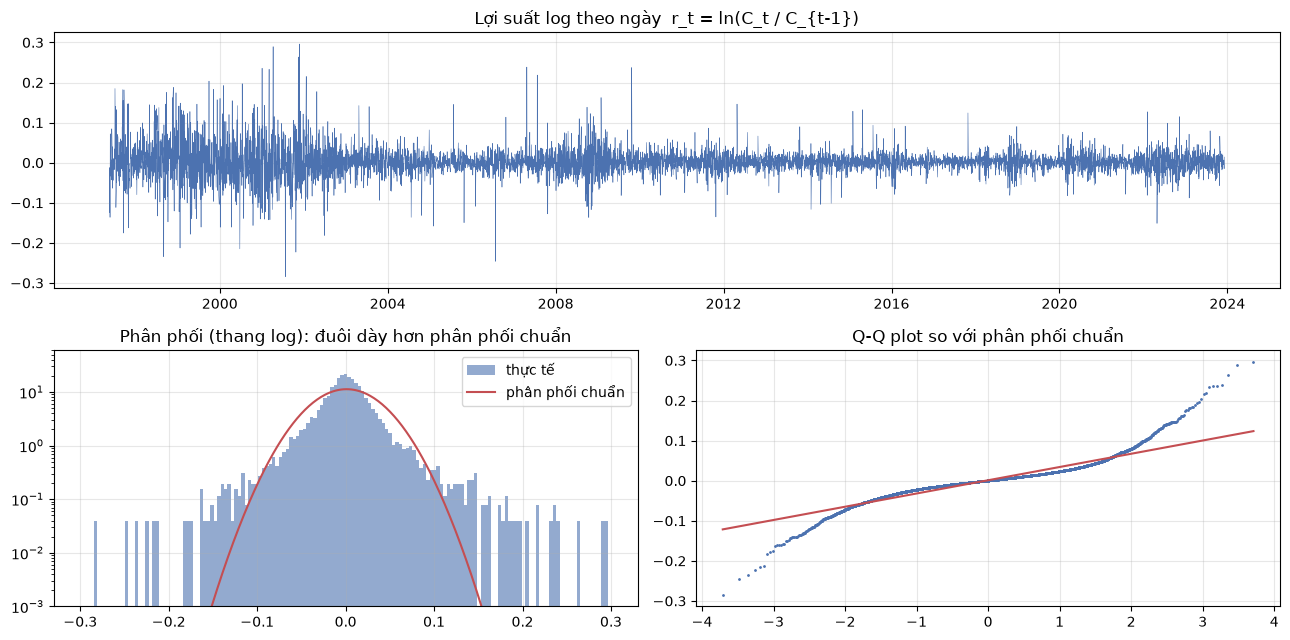

In [18]:
fig = plt.figure(figsize=(13, 6.5))
ax0 = fig.add_subplot(2, 1, 1)
ax0.plot(r.index, r, lw=0.4, c="#4C72B0")
ax0.set_title("Lợi suất log theo ngày  r_t = ln(C_t / C_{t-1})")
ax1 = fig.add_subplot(2, 2, 3)
xs = np.linspace(-0.3, 0.3, 400)
ax1.hist(r, bins=150, density=True, alpha=0.6, color="#4C72B0", label="thực tế")
ax1.plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), c="#C44E52", label="phân phối chuẩn")
ax1.set_yscale("log")
ax1.set_ylim(1e-3, 60)
ax1.set_title("Phân phối (thang log): đuôi dày hơn phân phối chuẩn")
ax1.legend()
ax2 = fig.add_subplot(2, 2, 4)
(osm, osr), (slope, icpt, _) = stats.probplot(r, dist="norm")
ax2.plot(osm, osr, ".", ms=2, c="#4C72B0")
ax2.plot(osm, slope * osm + icpt, c="#C44E52")
ax2.set_title("Q-Q plot so với phân phối chuẩn")
fig.tight_layout()
save(fig, "fig_amzn_returns.png")
plt.show()

Lợi suất trung bình 0,11%/ngày nhưng độ lệch chuẩn 3,5%/ngày, tức nhiễu lớn gấp
khoảng 30 lần tín hiệu xu hướng. Độ nhọn dư 9,3 (phân phối chuẩn là 0): có 63 ngày
biến động quá 4 độ lệch chuẩn, trong khi phân phối chuẩn chỉ kỳ vọng 0,4 ngày. Hình Q-Q cong lên ở hai đầu cũng nói điều đó. Hệ quả cho việc huấn luyện:
hàm mất mát MSE sẽ bị vài ngày cực đoan chi phối.

### 2.3. Phần nào của chuỗi có "trí nhớ"?

RNN chỉ có ích khi quá khứ chứa thông tin về tương lai. Hàm tự tương quan (ACF) đo
đúng điều đó: tương quan giữa chuỗi và chính nó dịch đi k ngày.

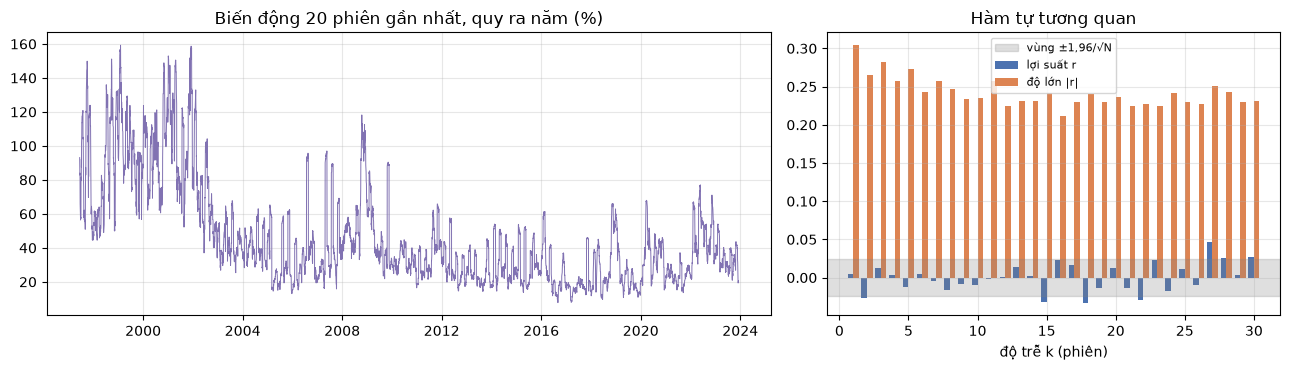

ACF cua r    tai k=1..5: [ 0.005 -0.027  0.013  0.003 -0.012]
ACF cua |r|  tai k=1..5: [0.304 0.265 0.282 0.257 0.273]
so do tre (trong 30) ma ACF cua r vuot bien +-0.024: 7
so do tre (trong 30) ma ACF cua |r| vuot bien: 30


In [19]:
nl = 30
acf_r = D.acf(r, nl)
acf_abs = D.acf(np.abs(r), nl)
band = 1.96 / np.sqrt(len(r))
vol20 = r.rolling(20).std() * np.sqrt(252)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
a1.plot(vol20.index, vol20 * 100, lw=0.7, c="#8172B2")
a1.set_title("Biến động 20 phiên gần nhất, quy ra năm (%)")
k = np.arange(1, nl + 1)
a2.bar(k - 0.2, acf_r[1:], width=0.4, label="lợi suất r", color="#4C72B0")
a2.bar(k + 0.2, acf_abs[1:], width=0.4, label="độ lớn |r|", color="#DD8452")
a2.axhspan(-band, band, color="gray", alpha=0.25, label="vùng ±1,96/√N")
a2.set_xlabel("độ trễ k (phiên)")
a2.set_title("Hàm tự tương quan")
a2.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_amzn_vol_acf.png")
plt.show()
print("ACF cua r    tai k=1..5:", np.round(acf_r[1:6], 3))
print("ACF cua |r|  tai k=1..5:", np.round(acf_abs[1:6], 3))
print("so do tre (trong 30) ma ACF cua r vuot bien +-%.3f: %d" % (band, (np.abs(acf_r[1:]) > band).sum()))
print("so do tre (trong 30) ma ACF cua |r| vuot bien: %d" % (np.abs(acf_abs[1:]) > band).sum())

Đây là kết quả quan trọng nhất của phần phân tích. **Bản thân lợi suất gần như không
có trí nhớ**: tự tương quan ở cả 30 độ trễ đều dưới 0,05 về trị tuyệt đối. Có 7 độ
trễ vượt biên ±1,96/√N nhưng dấu đổi qua lại không theo quy luật nào, và biên đó giả
định nhiễu trắng thuần, điều không đúng với một chuỗi có cụm biến động như thế này.
**Độ lớn của lợi suất thì có trí nhớ dài**: ACF của |r| khoảng 0,26-0,30 ở 5 độ trễ
đầu và vẫn còn 0,23 ở độ trễ 30. Đó là hiện tượng *cụm biến động*
(volatility clustering) thấy rõ trên đồ thị bên trái: những giai đoạn dao động mạnh
(2000-2002, 2008, 2020, 2022) kéo dài nhiều tháng chứ không xuất hiện rời rạc.

Nói cách khác, quá khứ gần như không cho biết ngày mai giá **tăng hay giảm**, nhưng
cho biết khá nhiều về việc ngày mai giá **dao động mạnh hay yếu**. Vì vậy notebook 03
và 04 đặt hai bài toán dự báo cho cùng một chuỗi:

| Bài toán | Mục tiêu | Kỳ vọng từ ACF |
|---|---|---|
| Dự báo lợi suất | `y_ret` = r_{t+1} | gần như không dự báo được |
| Dự báo biến động | `y_vol` = căn trung bình r² của 5 phiên t+1..t+5 | dự báo được một phần |

In [20]:
chk = pd.DataFrame({"r_next": f["ret"].shift(-1), "abs_r_next": f["ret"].shift(-1).abs(),
                    "ret": f["ret"], "abs_ret": f["ret"].abs(), "range": f["range"],
                    "relvol": f["relvol"]}).dropna()
tab = pd.DataFrame({
    "tuong_quan_voi_r_(t+1)": chk[["ret", "abs_ret", "range", "relvol"]].corrwith(chk["r_next"]),
    "tuong_quan_voi_|r|_(t+1)": chk[["ret", "abs_ret", "range", "relvol"]].corrwith(chk["abs_r_next"])})
print(tab.round(3))

         tuong_quan_voi_r_(t+1)  tuong_quan_voi_|r|_(t+1)
ret                       0.003                    -0.002
abs_ret                  -0.029                     0.305
range                     0.007                     0.441
relvol                    0.011                     0.140


Bảng trên kiểm tra riêng từng đặc trưng của ngày t. Không đặc trưng nào tương quan
đáng kể với lợi suất ngày mai (tất cả dưới 0,03 về trị tuyệt đối), nhưng biên độ
trong ngày `range` tương quan 0,44 với độ lớn lợi suất ngày mai và khối lượng tương
đối `relvol` cũng mang thông tin. Đây là lý do ba đặc trưng đầu vào được chọn là lợi
suất, biên độ và khối lượng tương đối: cả ba đều không phụ thuộc mức giá, nên cùng
một mô hình dùng được cho năm 1998 khi giá 1 USD lẫn năm 2023 khi giá 150 USD.

### 2.4. Khối lượng giao dịch và mức sụt giảm

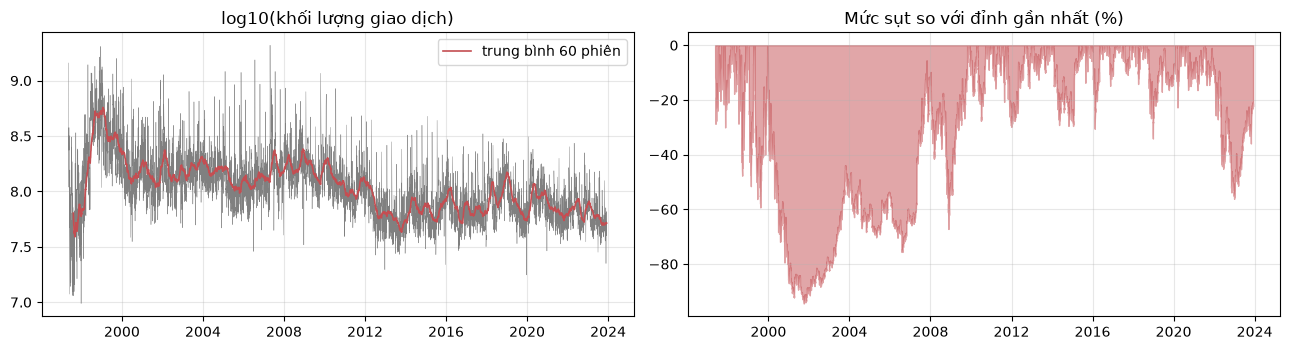

sut giam lon nhat -94.4%: dinh 1999-12-10 -> day 2001-09-28
sut giam lon nhat trong giai doan test: -56.1% (day 2022-12-28)


In [21]:
lv = np.log10(a["Volume"])
dd = f["close"] / f["close"].cummax() - 1
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6))
a1.plot(lv.index, lv, lw=0.3, c="gray")
a1.plot(lv.index, lv.rolling(60).mean(), c="#C44E52", lw=1.2, label="trung bình 60 phiên")
a1.set_title("log10(khối lượng giao dịch)")
a1.legend()
a2.fill_between(dd.index, dd * 100, 0, color="#C44E52", alpha=0.5)
a2.set_title("Mức sụt so với đỉnh gần nhất (%)")
fig.tight_layout()
save(fig, "fig_amzn_volume_drawdown.png")
plt.show()
trough = dd.idxmin()
peak = f["close"].loc[:trough].idxmax()
print("sut giam lon nhat %.1f%%: dinh %s -> day %s" % (100 * dd.min(), peak.date(), trough.date()))
dd22 = dd.loc["2021":]
print("sut giam lon nhat trong giai doan test: %.1f%% (day %s)" % (100 * dd22.min(), dd22.idxmin().date()))

Khối lượng tính theo số cổ phiếu đã điều chỉnh chia tách nên mức tuyệt đối thay đổi
theo thời kỳ; vì thế đặc trưng đưa vào mô hình là khối lượng *tương đối* so với 20
phiên trước đó chứ không phải khối lượng thô. Mức sụt giảm lớn nhất 94,4% (đỉnh
12/1999, đáy 09/2001). Giai đoạn test chứa một đợt giảm hơn 50% năm 2022, nên đây là
tập kiểm tra khó chứ không phải một giai đoạn tăng đều.

### 2.5. Cửa sổ trượt đưa vào RNN

In [22]:
S_ret = D.stock_splits("y_ret")
S_vol = D.stock_splits("y_vol")
for name, S_ in (("y_ret", S_ret), ("y_vol", S_vol)):
    print(name, {s: S_["X_" + s].shape for s in ("train", "val", "test")},
          "| ngay du bao dau tien cua test:", S_["date_test"][0].date())
print("thong ke chuan hoa (tap train):",
      {k: (round(S_ret["x_mu"][k], 4), round(S_ret["x_sd"][k], 4)) for k in S_ret["features"]})

y_ret {'train': (5363, 60, 3), 'val': (505, 60, 3), 'test': (736, 60, 3)} | ngay du bao dau tien cua test: 2021-01-04
y_vol {'train': (5359, 60, 3), 'val': (505, 60, 3), 'test': (736, 60, 3)} | ngay du bao dau tien cua test: 2020-12-28
thong ke chuan hoa (tap train): {'ret': (0.0013, 0.0375), 'range': (0.0408, 0.0331), 'relvol': (0.0017, 0.4529)}


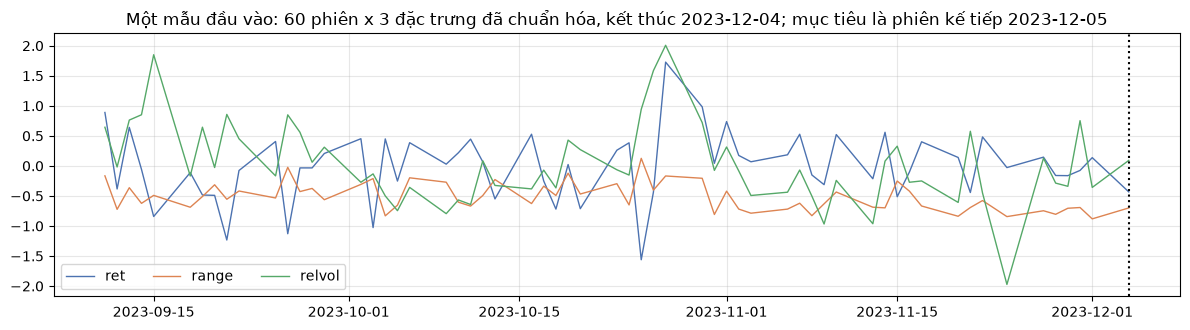

In [23]:
i = -1
w = S_ret["X_test"][i]
t_idx = S_ret["t_test"][i]
days = f.index[t_idx - 59:t_idx + 1]
fig, ax = plt.subplots(figsize=(12, 3.4))
for j, (name, col) in enumerate(zip(S_ret["features"], ["#4C72B0", "#DD8452", "#55A868"])):
    ax.plot(days, w[:, j], c=col, lw=1, label=name)
ax.axvline(days[-1], c="k", ls=":")
ax.set_title("Một mẫu đầu vào: 60 phiên x 3 đặc trưng đã chuẩn hóa, kết thúc %s; "
             "mục tiêu là phiên kế tiếp %s" % (days[-1].date(), S_ret["date_test"][i].date()))
ax.legend(ncol=3)
fig.tight_layout()
save(fig, "fig_amzn_window.png")
plt.show()

Mỗi mẫu là một ma trận 60 x 3 (60 phiên, 3 đặc trưng), đúng dạng `(batch, time,
feature)` mà `nn.LSTM(batch_first=True)` và `keras.layers.LSTM` nhận vào. Việc gán
mẫu cho tập train, validation hay test dựa trên ngày cuối cùng mà mục tiêu chạm tới,
nên với bài toán biến động 5 phiên, mẫu cuối của tập train dừng sớm hơn 4 phiên so
với bài toán lợi suất. Không mẫu train nào có mục tiêu rơi vào năm 2019 trở đi.

**Tóm tắt những gì phần phân tích quyết định cho phần mô hình:**

| Phát hiện | Quyết định |
|---|---|
| Churn: nhãn lệch 20/80 | đo bằng ROC-AUC, PR-AUC, F1; chọn ngưỡng trên validation |
| Churn: quan hệ chữ U theo tuổi và số sản phẩm | cần mô hình phi tuyến, giữ logistic làm mốc |
| Churn: không có trục thời gian thật | RNN đọc 11 đặc trưng như một chuỗi, kiểm tra thứ tự, so với MLP |
| AMZN: giá test vượt xa giá train | không đưa mức giá vào mô hình, dùng lợi suất và biên độ |
| AMZN: lợi suất không có trí nhớ, biến động thì có | đặt hai bài toán, mỗi bài có baseline riêng |
| AMZN: chuỗi có thứ tự | chia theo thời gian, chuẩn hóa bằng thống kê tập train |